# 相同邮件上的评价与错误分析
读取当前发布版本的保存预测。固定留出集用于回顾评估：发布修订前已观察旧模型成绩，不能视作全新独立确认。模型拟合、校准与阈值选择均未使用 Test。

In [1]:
from pathlib import Path
import os,json
if not Path('configs').exists() and Path('../configs').exists():os.chdir('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from spam_analysis.analysis.results import source_records,result_table,error_frame
from spam_analysis.experiments.runtime import ExperimentSession
plt.rcParams['font.sans-serif']=['Microsoft YaHei']
plt.rcParams['axes.unicode_minus']=False
engine=ExperimentSession()
print('结果版本：',engine.run_id)


结果版本： course-20261016


In [2]:
from spam_analysis.metrics import counts,metrics,threshold_table
from sklearn.metrics import confusion_matrix
y=np.array([0,0,1,1]);p=np.array([.2,.5,.5,.8])
display(counts(y,p>=.5),confusion_matrix(y,p>=.5,labels=[0,1]))
display(threshold_table(y,p))

{'tn': 1.0, 'fp': 1.0, 'fn': 0.0, 'tp': 2.0}

array([[1, 1],
       [0, 2]])

,threshold,tn,fp,fn,tp,macro_f1,ham_fpr,spam_recall
0,0.8,2,0,2,0,0.333333,0.0,0.0
1,0.8,2,0,1,1,0.733333,0.0,0.5
2,0.5,1,1,0,2,0.733333,0.5,1.0
3,0.2,0,2,0,2,0.333333,1.0,1.0


In [3]:
scope='trec06c' if engine.run_id=='frozen-v1' else 'combined'
results=result_table(engine.run_id,scope)
display(results[['model','n','accuracy','macro_f1','fp','fn','ham_fpr']])
threshold=engine.specifications[engine.main]['thresholds']['research']
evaluated=error_frame(engine.run_id,scope,engine.main,threshold)
assert len(evaluated)==int(results.set_index('model').loc[engine.main,'n'])

,model,n,accuracy,macro_f1,fp,fn,ham_fpr
0,B1,19820,0.967205,0.966100,434.0,216.0,0.052734
1,B2,19820,0.987538,0.987169,124.0,123.0,0.015067
2,S_char13,19820,0.993239,0.993036,78.0,56.0,0.009478
3,E1,19820,0.972503,0.971677,284.0,261.0,0.034508
4,E2,19820,0.994046,0.993870,60.0,58.0,0.007290


In [4]:
from spam_analysis.analysis.tables import reliability,assign_slices,slice_errors,length_edges
train=source_records('combined','train')
for field in ['source','language','length','quality']:
    print(field);display(slice_errors(evaluated,assign_slices(evaluated,field,length_edges(train))))

source


,group,count,errors,false_positive,false_negative,spam,ham,error_rate,ham_fpr,spam_miss_rate
0,Apache SpamAssassin,1225,32,18,14,403,822,0.026122,0.021898,0.034739
1,Enron-Spam,8884,78,37,41,4885,3999,0.008780,0.009252,0.008393
2,TREC06C,9711,8,5,3,6302,3409,0.000824,0.001467,0.000476


language


,group,count,errors,false_positive,false_negative,spam,ham,error_rate,ham_fpr,spam_miss_rate
0,中拉混合,1035,0,0,0,894,141,0.000000,0.000000,0.000000
1,中文字符为主,8524,6,3,3,5291,3233,0.000704,0.000928,0.000567
2,其他 / 难判,58,2,2,0,48,10,0.034483,0.200000,0.000000
3,拉丁字母为主,10039,110,55,55,5193,4846,0.010957,0.011350,0.010591
4,空正文,164,0,0,0,164,0,0.000000,NaN,0.000000


length


,group,count,errors,false_positive,false_negative,spam,ham,error_rate,ham_fpr,spam_miss_rate
0,"(-inf, 246.0]",4960,30,21,9,2469,2491,0.006048,0.008430,0.003645
1,"(1017.0, inf]",4984,38,20,18,2867,2117,0.007624,0.009447,0.006278
2,"(246.0, 407.0]",4706,16,10,6,2958,1748,0.003400,0.005721,0.002028
3,"(407.0, 1017.0]",5170,34,9,25,3296,1874,0.006576,0.004803,0.007585


quality


,group,count,errors,false_positive,false_negative,spam,ham,error_rate,ham_fpr,spam_miss_rate
0,可读正文,18277,118,60,58,10308,7969,0.006456,0.007529,0.005627
1,含损坏字符,1380,0,0,0,1119,261,0.000000,0.000000,0.000000
2,正文为空,163,0,0,0,163,0,0.000000,NaN,0.000000


,bin,lower,upper,count,mean_probability,spam_fraction
0,0,0.0,0.1,8212,0.001949,0.005602
1,1,0.1,0.2,16,0.138170,0.750000
2,2,0.2,0.3,4,0.227538,0.750000
3,3,0.3,0.4,2,0.350246,1.000000
4,4,0.4,0.5,2,0.471844,0.500000
5,5,0.5,0.6,5,0.559908,0.600000
6,6,0.6,0.7,6,0.658850,0.500000
7,7,0.7,0.8,6,0.757431,0.500000
8,8,0.8,0.9,14,0.859728,0.714286
9,9,0.9,1.0,11553,0.998473,0.996018


{'brier': 0.005435564764248827,
 'log_loss': 0.023578637909480987,
 'ece': 0.003850381006841285,
 'n': 19820}

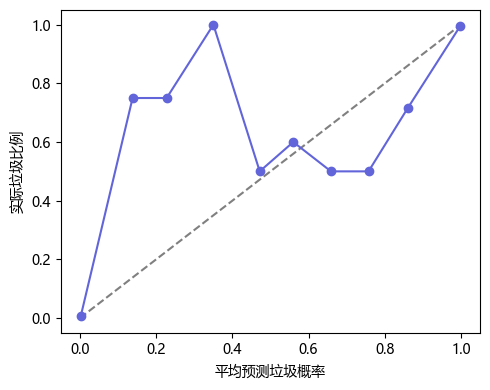

In [5]:
bins,calibration=reliability(evaluated)
display(bins,calibration)
assert bins['count'].sum()==len(evaluated)
used=bins.query('count>0');plt.figure(figsize=(5,4));plt.plot([0,1],[0,1],'--',color='gray');plt.plot(used.mean_probability,used.spam_fraction,'o-',color='#6265d9');plt.xlabel('平均预测垃圾概率');plt.ylabel('实际垃圾比例');plt.tight_layout();plt.show()

高分不保证单封正确。可靠性曲线比较区间平均预测与实际垃圾比例，Brier 衡量概率误差；小分组误差率不稳定。旧公开语料高分也不能证明现代中文邮箱效果。